<a href="https://colab.research.google.com/github/vitriadwiernita/TUGAS-ANMUL-KELOMPOK-1-CLUSTER-/blob/main/KEL_1_CLUSTERING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **KELOMPOK 1**
Vitria Dwi Ernita

Jamottan Fierdianto A Sihite

# Clustering

K-Means Clustering pada dataset konsumsi kopi dan kesehatan.

## Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Import Datasets

In [ ]:
# Upload dataset jika menggunakan Google Colab
from google.colab import files
uploaded = files.upload()

coffee = pd.read_csv('synthetic_coffee_health_10000.csv')
coffee.info()

Saving synthetic_coffee_health_10000.csv to synthetic_coffee_health_10000.csv
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       10000 non-null  int64  
 1   Age                      10000 non-null  int64  
 2   Gender                   10000 non-null  object 
 3   Country                  10000 non-null  object 
 4   Coffee_Intake            10000 non-null  float64
 5   Caffeine_mg              10000 non-null  float64
 6   Sleep_Hours              10000 non-null  float64
 7   Sleep_Quality            10000 non-null  object 
 8   BMI                      10000 non-null  float64
 9   Heart_Rate               10000 non-null  int64  
 10  Stress_Level             10000 non-null  object 
 11  Physical_Activity_Hours  10000 non-null  float64
 12  Health_Issues            4059 non-null   object 
 13 

In [ ]:
coffee.head()

,ID,Age,Gender,Country,Coffee_Intake,Caffeine_mg,Sleep_Hours,Sleep_Quality,BMI,Heart_Rate,Stress_Level,Physical_Activity_Hours,Health_Issues,Occupation,Smoking,Alcohol_Consumption
0,1,40,Male,Germany,3.5,328.1,7.5,Good,24.9,78,Low,14.5,NaN,Other,0,0
1,2,33,Male,Germany,1.0,94.1,6.2,Good,20.0,67,Low,11.0,NaN,Service,0,0
2,3,42,Male,Brazil,5.3,503.7,5.9,Fair,22.7,59,Medium,11.2,Mild,Office,0,0
3,4,53,Male,Germany,2.6,249.2,7.3,Good,24.7,71,Low,6.6,Mild,Other,0,0
4,5,32,Female,Spain,3.1,298.0,5.3,Fair,24.1,76,Medium,8.5,Mild,Student,0,1


## K-Means Clustering

In [ ]:
coffee.head()

,ID,Age,Gender,Country,Coffee_Intake,Caffeine_mg,Sleep_Hours,Sleep_Quality,BMI,Heart_Rate,Stress_Level,Physical_Activity_Hours,Health_Issues,Occupation,Smoking,Alcohol_Consumption
0,1,40,Male,Germany,3.5,328.1,7.5,Good,24.9,78,Low,14.5,NaN,Other,0,0
1,2,33,Male,Germany,1.0,94.1,6.2,Good,20.0,67,Low,11.0,NaN,Service,0,0
2,3,42,Male,Brazil,5.3,503.7,5.9,Fair,22.7,59,Medium,11.2,Mild,Office,0,0
3,4,53,Male,Germany,2.6,249.2,7.3,Good,24.7,71,Low,6.6,Mild,Other,0,0
4,5,32,Female,Spain,3.1,298.0,5.3,Fair,24.1,76,Medium,8.5,Mild,Student,0,1


In [ ]:
# check missing values
coffee.isna().sum()

,0
ID,0
Age,0
Gender,0
Country,0
Coffee_Intake,0
Caffeine_mg,0
Sleep_Hours,0
Sleep_Quality,0
BMI,0
Heart_Rate,0


In [ ]:
# check duplicates
coffee.duplicated().sum()

np.int64(0)

### Data preprocessing

Kolom `ID` tidak digunakan karena hanya merupakan identitas responden. Kolom kategori perlu diubah menjadi angka agar dapat diproses oleh K-Means. Nilai kosong pada `Health_Issues` diisi dengan kategori `Unknown`, bukan dianggap sebagai tidak memiliki masalah kesehatan.

In [ ]:
# Memilih fitur yang digunakan untuk clustering
numeric_features = [
    'Age',
    'Coffee_Intake',
    'Caffeine_mg',
    'Sleep_Hours',
    'BMI',
    'Heart_Rate',
    'Physical_Activity_Hours',
    'Smoking',
    'Alcohol_Consumption'
]

categorical_features = [
    'Gender',
    'Country',
    'Sleep_Quality',
    'Stress_Level',
    'Health_Issues',
    'Occupation'
]

# Mengambil fitur yang akan digunakan
coffee_features = coffee[numeric_features + categorical_features].copy()

# Mengatasi nilai kosong pada kolom Health_Issues
coffee_features['Health_Issues'] = coffee_features['Health_Issues'].fillna('Unknown')

# Mengubah kolom kategori menjadi dummy/angka
coffee_encoded = pd.get_dummies(coffee_features, columns=categorical_features, dtype=int)

coffee_encoded.head()

,Age,Coffee_Intake,Caffeine_mg,Sleep_Hours,BMI,Heart_Rate,Physical_Activity_Hours,Smoking,Alcohol_Consumption,Gender_Female,...,Stress_Level_Medium,Health_Issues_Mild,Health_Issues_Moderate,Health_Issues_Severe,Health_Issues_Unknown,Occupation_Healthcare,Occupation_Office,Occupation_Other,Occupation_Service,Occupation_Student
0,40,3.5,328.1,7.5,24.9,78,14.5,0,0,0,...,0,0,0,0,1,0,0,1,0,0
1,33,1.0,94.1,6.2,20.0,67,11.0,0,0,0,...,0,0,0,0,1,0,0,0,1,0
2,42,5.3,503.7,5.9,22.7,59,11.2,0,0,0,...,1,1,0,0,0,0,1,0,0,0
3,53,2.6,249.2,7.3,24.7,71,6.6,0,0,0,...,0,1,0,0,0,0,0,1,0,0
4,32,3.1,298.0,5.3,24.1,76,8.5,0,1,1,...,1,1,0,0,0,0,0,0,0,1


In [ ]:
# minmax scaler
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
coffee_scaled = scaler.fit_transform(coffee_encoded)

pd.DataFrame(coffee_scaled, columns=coffee_encoded.columns).describe()

,Age,Coffee_Intake,Caffeine_mg,Sleep_Hours,BMI,Heart_Rate,Physical_Activity_Hours,Smoking,Alcohol_Consumption,Gender_Female,...,Stress_Level_Medium,Health_Issues_Mild,Health_Issues_Moderate,Health_Issues_Severe,Health_Issues_Unknown,Occupation_Healthcare,Occupation_Office,Occupation_Other,Occupation_Service,Occupation_Student
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,...,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.0000
mean,0.273373,0.306004,0.305538,0.519460,0.387365,0.349454,0.499136,0.20040,0.300700,0.500100,...,0.205000,0.357900,0.046300,0.001700,0.59410,0.196400,0.207300,0.203800,0.195700,0.1968
std,0.180015,0.176859,0.176533,0.174579,0.168380,0.166491,0.287679,0.40032,0.458585,0.500025,...,0.403722,0.479406,0.210145,0.041198,0.49109,0.397294,0.405393,0.402842,0.396758,0.3976
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.0000
25%,0.129032,0.182927,0.177816,0.400000,0.271552,0.237288,0.246667,0.00000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.0000
50%,0.258065,0.304878,0.301679,0.514286,0.387931,0.355932,0.500000,0.00000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,1.00000,0.000000,0.000000,0.000000,0.000000,0.0000
75%,0.403226,0.426829,0.425509,0.642857,0.500000,0.457627,0.746667,0.00000,1.000000,1.000000,...,0.000000,1.000000,0.000000,0.000000,1.00000,0.000000,0.000000,0.000000,0.000000,0.0000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.0000


In [ ]:
# elbow method from k=1 to k=10
from sklearn.cluster import KMeans

# track sum of squared error
sse = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(coffee_scaled)
    sse.append(kmeans.inertia_)

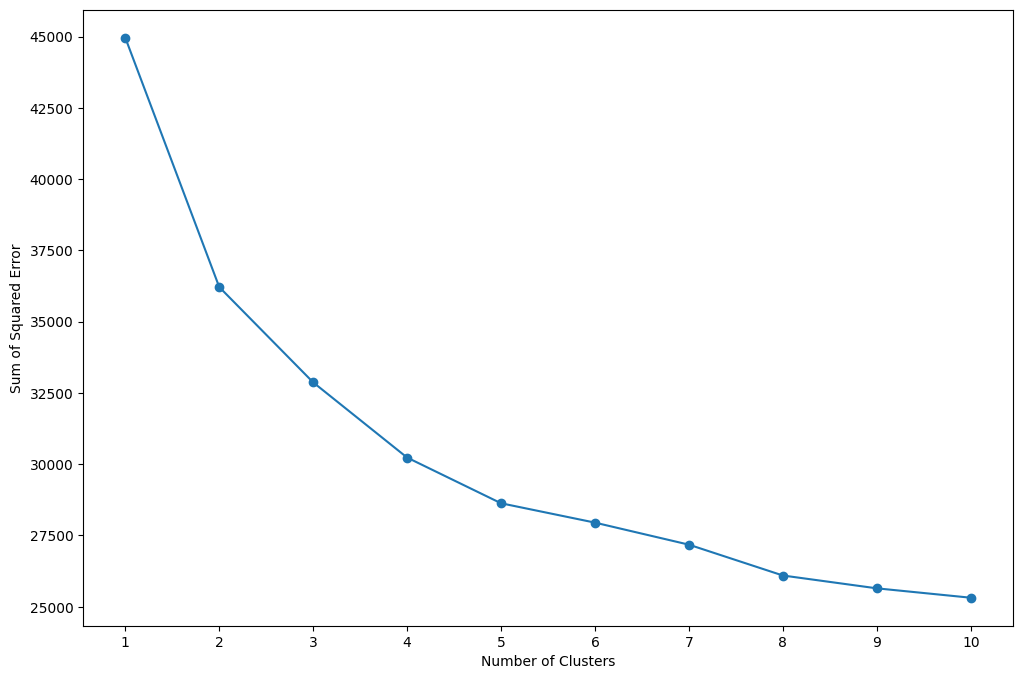

In [ ]:
# draw the SSE decline progression
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))
plt.plot(range(1, 11), sse, marker='o')
plt.xticks(range(1, 11))
plt.xlabel('Number of Clusters')
plt.ylabel('Sum of Squared Error')
plt.show()

### Davies-Bouldin Index (DB Index)

Selain melihat grafik Elbow, kita cek nilai Davies-Bouldin Index untuk K=2 sampai K=10. Nilai DB Index yang lebih kecil menunjukkan hasil pengelompokan yang lebih baik.


In [ ]:
from sklearn.metrics import davies_bouldin_score

db_index = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(coffee_scaled)
    dbi = davies_bouldin_score(coffee_scaled, labels)
    db_index.append(dbi)

db_results = pd.DataFrame({
    'K': range(2, 11),
    'Davies-Bouldin Index': db_index
})
db_results


,K,Davies-Bouldin Index
0,2,1.880762
1,3,2.221436
2,4,2.112348
3,5,2.062176
4,6,2.222912
5,7,2.506308
6,8,2.387133
7,9,2.181411
8,10,2.572686


In [ ]:
# Menentukan K dengan nilai DB Index paling rendah
best_k = db_results.loc[db_results['Davies-Bouldin Index'].idxmin(), 'K']
print('Jumlah cluster terbaik berdasarkan DB Index:', best_k)


Jumlah cluster terbaik berdasarkan DB Index: 2


**Hasil pengecekan:** berdasarkan perhitungan pada dataset ini, nilai DB Index terendah diperoleh pada **K=2** (sekitar **1.881**). Jadi, jumlah cluster yang digunakan pada proses K-Means berikutnya adalah 2.

Catatan: hasil DB Index digunakan sebagai salah satu pertimbangan bersama grafik Elbow, bukan jaminan bahwa jumlah cluster tersebut selalu paling bermakna secara substantif.

In [ ]:
# retrain k-means with optimal k berdasarkan DB Index
kmeans = KMeans(n_clusters=int(best_k), random_state=42, n_init=10)
kmeans.fit(coffee_scaled)

# assign class label to coffee df
coffee['label'] = kmeans.labels_
coffee.head()

,ID,Age,Gender,Country,Coffee_Intake,Caffeine_mg,Sleep_Hours,Sleep_Quality,BMI,Heart_Rate,Stress_Level,Physical_Activity_Hours,Health_Issues,Occupation,Smoking,Alcohol_Consumption,label
0,1,40,Male,Germany,3.5,328.1,7.5,Good,24.9,78,Low,14.5,NaN,Other,0,0,1
1,2,33,Male,Germany,1.0,94.1,6.2,Good,20.0,67,Low,11.0,NaN,Service,0,0,1
2,3,42,Male,Brazil,5.3,503.7,5.9,Fair,22.7,59,Medium,11.2,Mild,Office,0,0,0
3,4,53,Male,Germany,2.6,249.2,7.3,Good,24.7,71,Low,6.6,Mild,Other,0,0,1
4,5,32,Female,Spain,3.1,298.0,5.3,Fair,24.1,76,Medium,8.5,Mild,Student,0,1,0


In [ ]:
# compute mean of each numeric feature column by group by label
coffee.groupby('label')[numeric_features].mean()

,Age,Coffee_Intake,Caffeine_mg,Sleep_Hours,BMI,Heart_Rate,Physical_Activity_Hours,Smoking,Alcohol_Consumption
label,,,,,,,,,
0,34.805712,2.832780,269.215111,5.217735,23.974859,71.106609,7.505148,0.196280,0.293258
1,35.010874,2.369838,225.139991,7.247332,23.992030,70.407211,7.479239,0.202175,0.303906


Cluster interpretation?

Bandingkan rata-rata konsumsi kopi, asupan kafein, durasi tidur, BMI, detak jantung, aktivitas fisik, dan kebiasaan merokok/minum alkohol pada setiap cluster. Gunakan hasil tersebut untuk memberi gambaran karakteristik tiap kelompok. Dataset ini bersifat sintetis, jadi hasilnya tidak boleh dianggap sebagai kesimpulan tentang populasi nyata atau hubungan sebab-akibat.

# Selesai